# COU 07506 Digital Signal Processing Week 01: Setting Up the DSP Laboratory

Name: [Jina lako]
Class: BEng24...
Group: [Kundi lako]
Registration No.: [Namba yako ya usajili]
Date: 2026-11-23

Instructor checkpoints signed: [ ]1 [ ]2

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

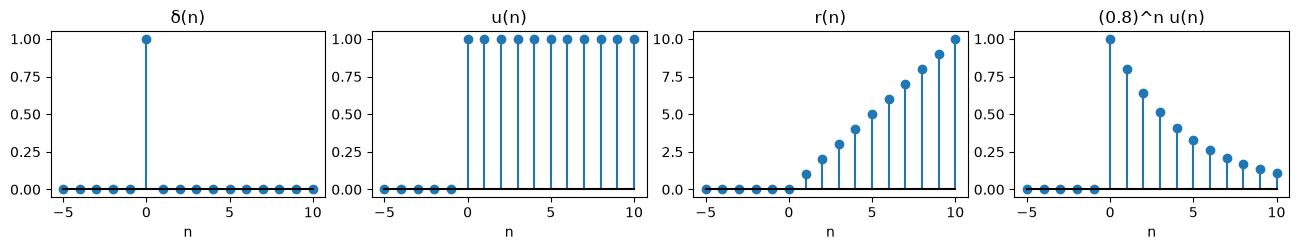

In [2]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)      # unit impulse
step = (n >= 0).astype(float)       # unit step
ramp = n * step                     # unit ramp
expo = (0.8 ** n) * step            # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"],
):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")

plt.tight_layout()
plt.show()

# Task 1.2 (Part 1): Exponential signals for different values of a

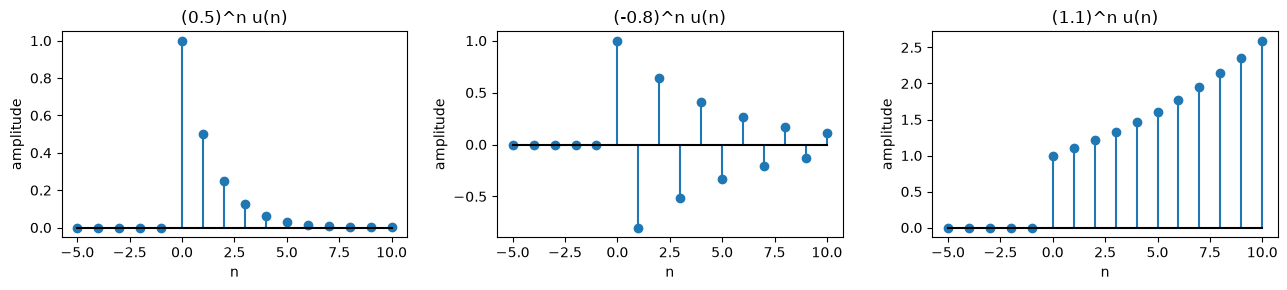

In [4]:
a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, a in zip(axes, a_values):
    x_a = (a ** n) * step
    ax.stem(n, x_a, basefmt="k-")
    ax.set_title(f"({a})^n u(n)")
    ax.set_xlabel("n")
    ax.set_ylabel("amplitude")

plt.tight_layout()
plt.show()

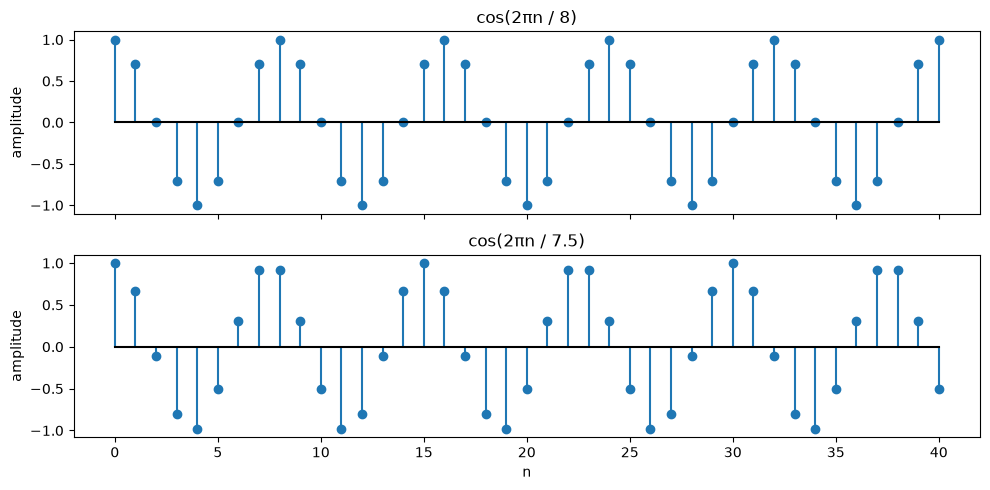

In [9]:
n_cos = np.arange(0, 41)
c1 = np.cos(2 * np.pi * n_cos / 8)
c2 = np.cos(2 * np.pi * n_cos / 7.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

axes[0].stem(n_cos, c1, basefmt="k-")
axes[0].set_title("cos(2πn / 8)")
axes[0].set_ylabel("amplitude")

axes[1].stem(n_cos, c2, basefmt="k-")
axes[1].set_title("cos(2πn / 7.5)")
axes[1].set_xlabel("n")
axes[1].set_ylabel("amplitude")

plt.tight_layout()
plt.show()

#Observation (Task 1.2 Part 2):**
* **cos(2πn / 8)** repeats its pattern exactly every **8 samples** ($N = 8$), because its normalized frequency is $1/8$, giving an exact integer period of 8 samples.
* **cos(2πn / 7.5)** does not repeat with a simple 8-sample cycle (its period is $N = 15$ samples since $1/7.5 = 2/15$), so the sample heights shift across cycles.

# Task 1.3 - Working with audio

fs = 44100 Hz, duration = 8.57 s, samples = 377880


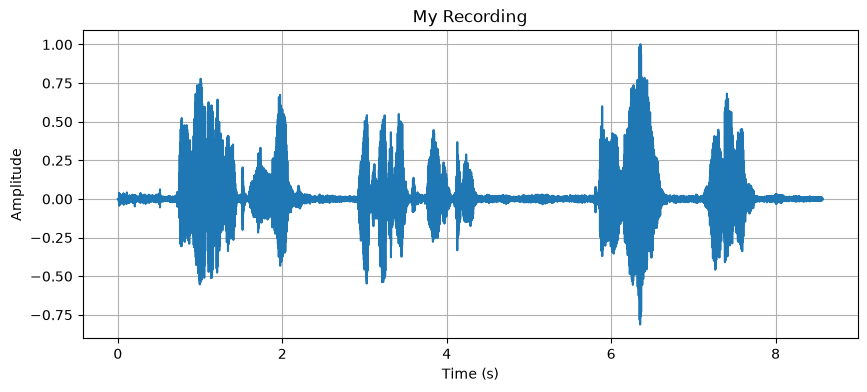

In [19]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import Audio

fname = "my_voice.wav"
loaded = False

if os.path.exists(fname):
    try:
        fs, x = wavfile.read(fname)
        if x.ndim > 1:
            x = x.mean(axis=1)  # convert stereo to mono
        x = x.astype(float)
        max_val = np.max(np.abs(x))
        if max_val > 0:
            x = x / max_val  # normalize to [-1, 1]
        loaded = True
    except Exception as e:
        print("Could not read file as a valid WAV file:", e)
        print("Using fallback test signal...")

if not loaded:
    fs = 16000
    t_fb = np.arange(0, 2, 1 / fs)
    x = 0.5 * np.sin(2 * np.pi * 440 * t_fb) * np.exp(-t_fb)

t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x) / fs:.2f} s, samples = {len(x)}")

plt.figure(figsize=(10, 4))
plt.plot(t, x)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("My Recording" if loaded else "Fallback Test Signal (440 Hz)")
plt.grid(True)
plt.show()

Audio(x, rate=fs)

### Task 1.4 - The same in Octave
Executed the four elementary discrete-time sequences in GNU Octave for $n = -5:10$ and verified the resulting stem plots against the Python/NumPy implementation.

**Key syntax differences between Python/NumPy and GNU Octave:**
- **Index ranges:** Octave uses inclusive colon ranges (`-5:10`), whereas NumPy uses `np.arange(-5, 11)` (upper bound excluded).
- **Element-wise operators:** Octave requires `.*` and `.^` for element-wise multiplication and exponentiation on vectors, whereas NumPy arrays use `*` and `**`.
- **Boolean-to-numeric conversion:** Octave uses `double(n >= 0)`, while NumPy uses `(n >= 0).astype(float)`.
- **Subplot indexing:** Octave `subplot(1, 4, k)` uses 1-based indexing (`1` to `4`), whereas Matplotlib `axes` arrays use 0-based indexing (`0` to `3`).